# African Telecom Stocks: A Time Series Analysis

Comparing **Airtel Africa**, **MTN Group** and **Vodacom** (2020 to 2025) with Pandas time series tools, plus a local snapshot of **TNM vs Airtel Malawi** from the Malawi Stock Exchange (MSE) Q3 2026 report.

**Tools:** Python, Pandas, yfinance, Matplotlib, Jupyter Notebook

**Why these tickers?** yfinance does not carry MSE-listed shares (TNM, Airtel Malawi). Airtel Malawi's parent, Airtel Africa, trades in London, and MTN and Vodacom are the two largest listed telecoms on the Johannesburg exchange, so they give a daily price history for the same industry.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})

TICKERS = {"AAF.L": "Airtel Africa", "MTN.JO": "MTN Group", "VOD.JO": "Vodacom"}
START, END = "2020-01-01", "2025-12-31"

## 1. Download the data

In [2]:
frames = {}
for ticker, name in TICKERS.items():
    df = yf.Ticker(ticker).history(start=START, end=END, auto_adjust=True)
    df.index = df.index.tz_localize(None)       # drop timezone for clean plotting
    df.index.name = "Date"
    frames[name] = df[["Open", "High", "Low", "Close", "Volume"]]
    print(f"{name:14s} {ticker:7s} rows: {len(df):5d}  {df.index.min().date()} -> {df.index.max().date()}")

frames["Airtel Africa"].head()

Airtel Africa  AAF.L   rows:  1514  2020-01-02 -> 2025-12-30
MTN Group      MTN.JO  rows:  1499  2020-01-02 -> 2025-12-30
Vodacom        VOD.JO  rows:  1499  2020-01-02 -> 2025-12-30


,Open,High,Low,Close,Volume
Date,,,,,
2020-01-02,76.254980,80.444271,76.254980,78.598991,1086111
2020-01-03,78.997986,79.297224,77.152706,78.299774,995180
2020-01-06,79.696184,79.720125,76.105368,78.249878,894623
2020-01-07,76.803596,79.496706,76.703853,79.097733,1073498
2020-01-08,78.349636,78.499248,77.003074,77.551674,814587


## 2. Dates as the index
Each DataFrame already uses `Date` as a `DatetimeIndex`. Confirm it and check for gaps or missing values.

In [3]:
for name, df in frames.items():
    assert isinstance(df.index, pd.DatetimeIndex) and df.index.is_monotonic_increasing
    print(name, "| missing values:", int(df.isna().sum().sum()))

Airtel Africa | missing values: 0
MTN Group | missing values: 0
Vodacom | missing values: 0


## 3. Closing prices over time
Prices are in different currencies (pence and South African cents), so raw levels are not directly comparable. The second chart rebases each to 100 at the start.

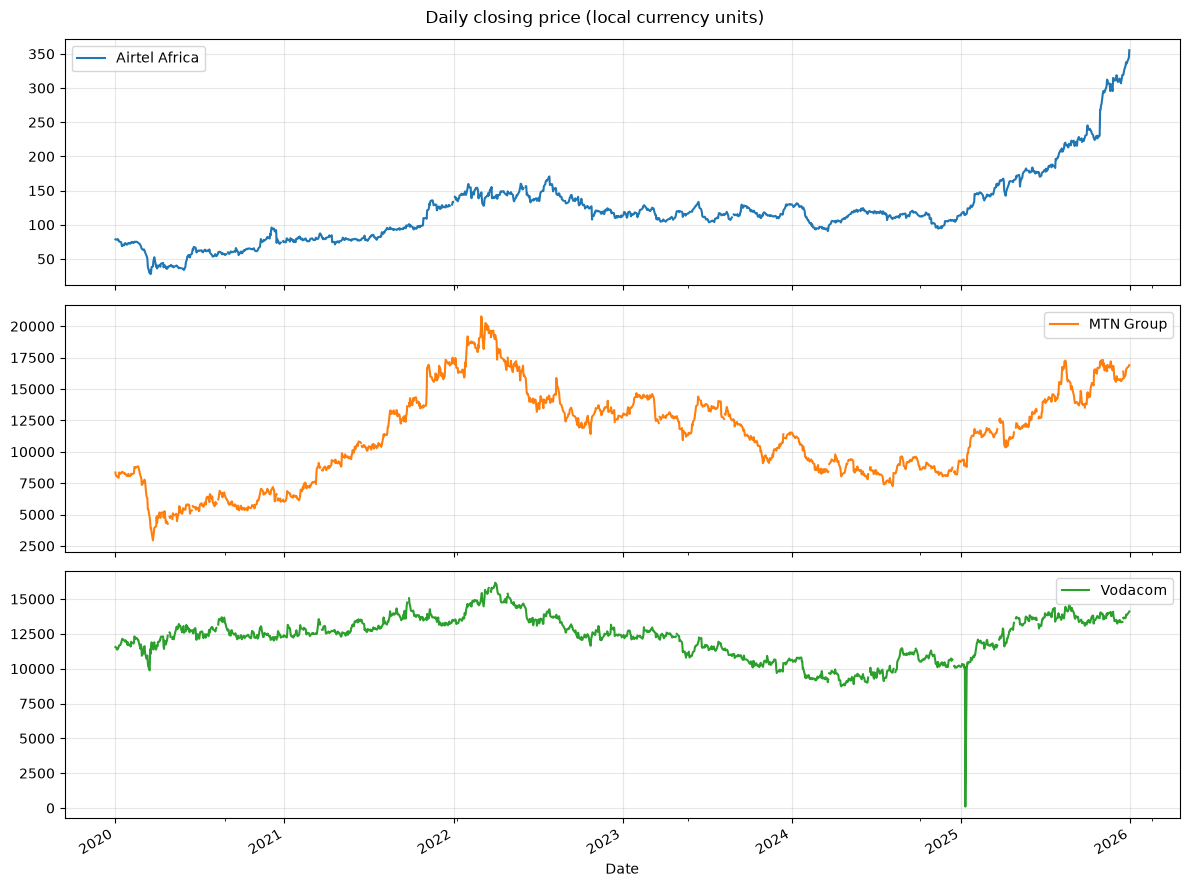

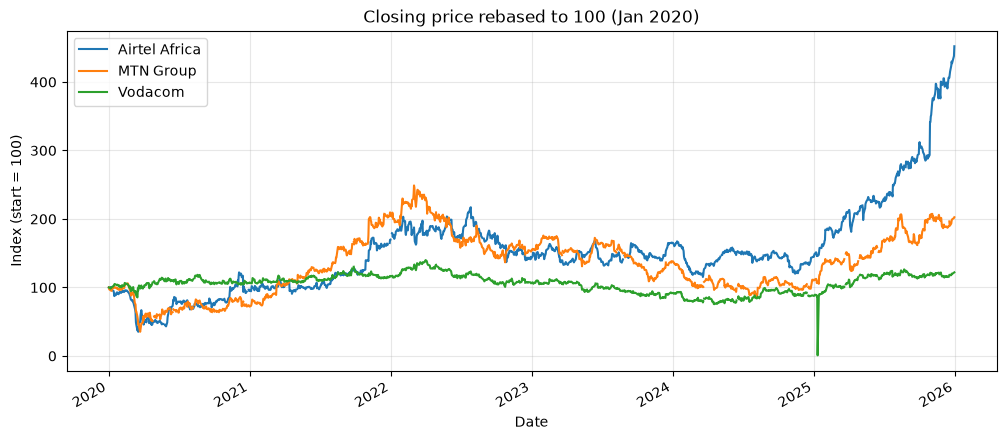

In [4]:
close = pd.DataFrame({name: df["Close"] for name, df in frames.items()})

close.plot(subplots=True, figsize=(12, 9), title="Daily closing price (local currency units)")
plt.tight_layout(); plt.show()

rebased = close / close.bfill().iloc[0] * 100
rebased.plot(title="Closing price rebased to 100 (Jan 2020)")
plt.ylabel("Index (start = 100)"); plt.show()

## 4. Resampling: weekly and monthly
`.resample()` turns daily data into longer-horizon trends. Closing price uses the last observation of each period.

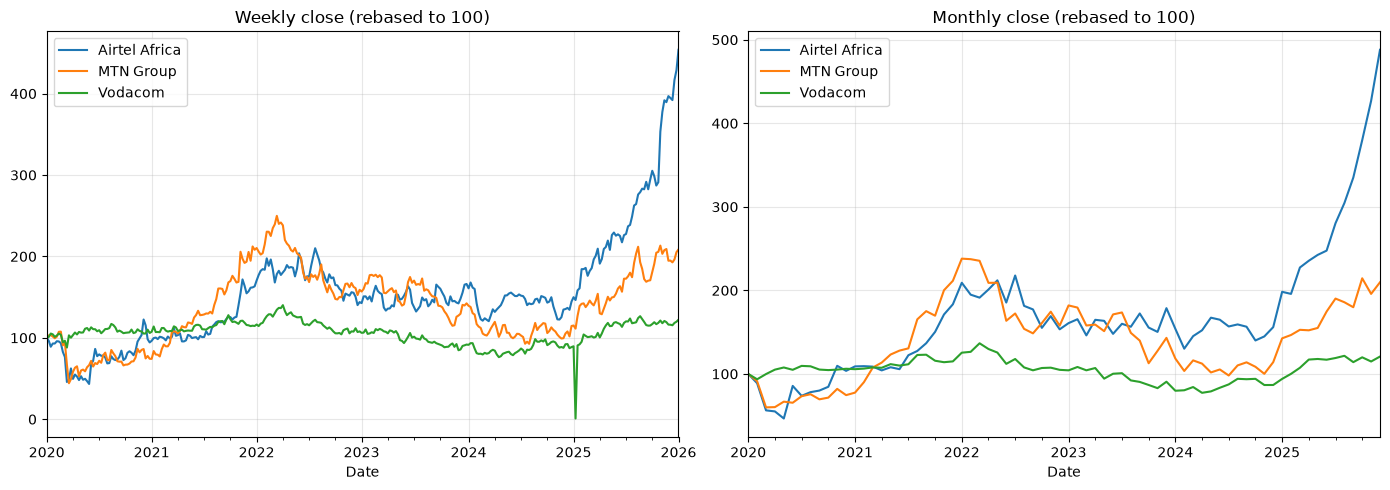

Average monthly return (%):
Airtel Africa    3.19
MTN Group        1.69
Vodacom          0.40
dtype: float64
Monthly volatility (std, %):
Airtel Africa    14.72
MTN Group        11.25
Vodacom           5.25
dtype: float64


In [5]:
weekly  = close.resample("W").last()
monthly = close.resample("ME").last()      

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
(weekly / weekly.bfill().iloc[0] * 100).plot(ax=axes[0], title="Weekly close (rebased to 100)")
(monthly / monthly.bfill().iloc[0] * 100).plot(ax=axes[1], title="Monthly close (rebased to 100)")
plt.tight_layout(); plt.show()

monthly_returns = monthly.pct_change().dropna() * 100
print("Average monthly return (%):"); print(monthly_returns.mean().round(2))
print("Monthly volatility (std, %):"); print(monthly_returns.std().round(2))

## 5. Moving averages: 20-day and 200-day
The 20-day average shows short-term direction; the 200-day shows the long-term trend. When the 20-day crosses above the 200-day, traders call it a *golden cross*; below is a *death cross*.

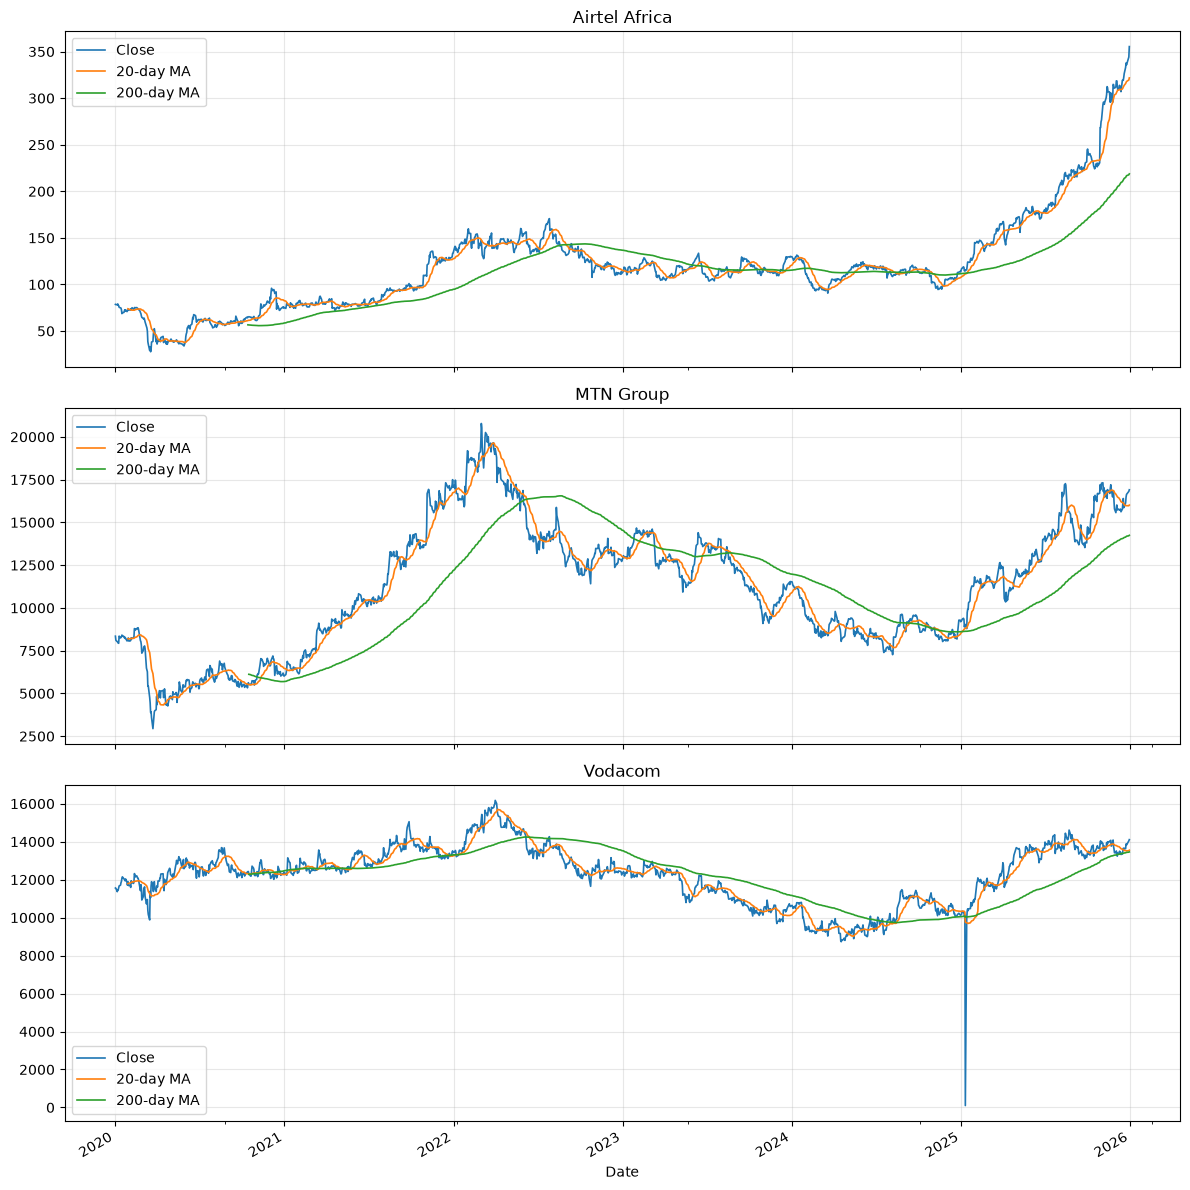

In [6]:
fig, axes = plt.subplots(len(frames), 1, figsize=(12, 4 * len(frames)), sharex=True)
for ax, (name, df) in zip(axes, frames.items()):
    ma = pd.DataFrame({
        "Close": df["Close"],
        "20-day MA": df["Close"].rolling(20).mean(),
        "200-day MA": df["Close"].rolling(200).mean(),
    })
    ma.plot(ax=ax, title=name, lw=1.2)
plt.tight_layout(); plt.show()

In [7]:
# Where does each stock end the period relative to its 200-day average?
for name, df in frames.items():
    last = df["Close"].iloc[-1]; ma200 = df["Close"].rolling(200).mean().iloc[-1]
    print(f"{name:14s} close vs 200-day MA: {(last/ma200 - 1)*100:+.1f}%")

Airtel Africa  close vs 200-day MA: +62.5%
MTN Group      close vs 200-day MA: +18.7%
Vodacom        close vs 200-day MA: +4.8%


## 6. Trading volume comparison

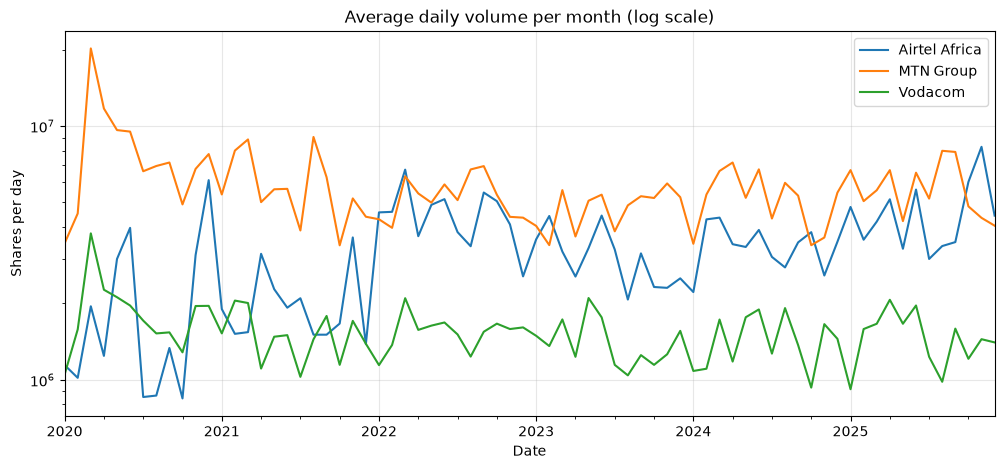

,Avg daily volume,Median daily volume,Peak day
Airtel Africa,3280655,2393012,82461685
MTN Group,5881375,4789886,82254233
Vodacom,1548444,1296895,11729490


In [8]:
volume = pd.DataFrame({name: df["Volume"] for name, df in frames.items()})

volume.resample("ME").mean().plot(logy=True, title="Average daily volume per month (log scale)")
plt.ylabel("Shares per day"); plt.show()

summary = pd.DataFrame({
    "Avg daily volume": volume.mean(),
    "Median daily volume": volume.median(),
    "Peak day": volume.max(),
}).round(0).astype(int)
summary

## 7. Local snapshot: TNM vs Airtel Malawi (MSE, Q3 2026)

yfinance has no feed for the Malawi Stock Exchange, so this section uses figures from the MSE *Quarterly Market Performance Report, Q3 2026* (July to September). It is a single-quarter summary, not a daily history, so no moving averages here.

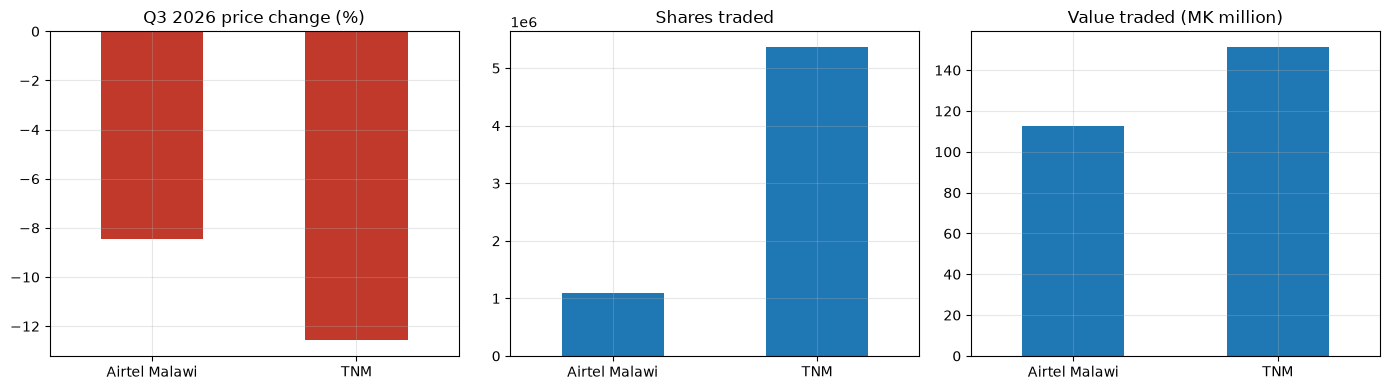

,Open (MK),Close (MK),Price change (%),Volume (shares),Value (MK),Trades,Avg price per share traded (MK)
Airtel Malawi,111.29,101.89,-8.45,1088106,1.126510e+08,409,103.53
TNM,29.17,25.50,-12.58,5370585,1.514504e+08,327,28.20


In [9]:
mse = pd.DataFrame({
    "Open (MK)":   [111.29, 29.17],
    "Close (MK)":  [101.89, 25.50],
    "Price change (%)": [-8.45, -12.58],
    "Volume (shares)":  [1_088_106, 5_370_585],
    "Value (MK)":       [112_650_993.34, 151_450_361.66],
    "Trades":           [409, 327],
}, index=["Airtel Malawi", "TNM"])
mse["Avg price per share traded (MK)"] = (mse["Value (MK)"] / mse["Volume (shares)"]).round(2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
mse["Price change (%)"].plot.bar(ax=axes[0], color=["#c0392b"]*2, title="Q3 2026 price change (%)", rot=0)
mse["Volume (shares)"].plot.bar(ax=axes[1], title="Shares traded", rot=0)
mse["Value (MK)"].div(1e6).plot.bar(ax=axes[2], title="Value traded (MK million)", rot=0)
plt.tight_layout(); plt.show()
mse

## 8. Takeaways

- **Trend:** Airtel Africa ended the period highest on the rebased chart, at roughly 4.5x its January 2020 level, against about 2x for MTN and about 1.2x for Vodacom. (The Vodacom line also shows a one-day collapse to almost zero near the start of 2025. That is a bad data point from Yahoo, not a real crash; section 10 finds and removes it.)
- **Momentum:** all three finished above their 200-day average: Airtel Africa +62.5%, MTN +18.7%, Vodacom +4.8%.
- **Risk and return:** the biggest average monthly gains came with the biggest swings. Airtel Africa averaged +3.19% a month with a 14.72% standard deviation, MTN +1.69% with 11.25%, Vodacom +0.40% with 5.25%. (Arithmetic monthly averages overstate compounded growth when volatility is high.)
- **Liquidity:** MTN trades the most shares (5.88M a day on average), then Airtel Africa (3.28M) and Vodacom (1.55M), so MTN is about 3.8x as liquid as Vodacom by share count. Averages for MTN and Airtel Africa are pulled up by single days of over 82M shares (medians are 4.79M and 2.39M). Share counts are not value traded, so this is not a like-for-like liquidity measure across currencies.
- **Malawi:** TNM and Airtel Malawi both fell in Q3 2026 (-12.58% and -8.45%), part of a market-wide decline where the MASI lost 6.44%. TNM traded more shares but at a far lower price per share, so Airtel Malawi still traded nearly as much by value.

**Limitations:** the main analysis uses parent or regional peers rather than the Malawi-listed shares; local figures come from a single quarterly report; Part 1 prices end in December 2025 and include the uncleaned Vodacom data point.

---
# Part 2: From analysis to a prediction pipeline

Part 1 describes what happened. Part 2 asks a harder question: **can anything known at today's close predict tomorrow's direction or return?**

The reusable code lives in `src/` (`data.py`, `features.py`, `train.py`, `backtest.py`) and `run_pipeline.py` reproduces everything below from the command line. This notebook walks through it and shows the results.

Rules for this section:
- Every feature for day *t* uses only data available at the close of day *t* (checked by an automated test in `tests/`).
- Train/test splits are **chronological** (walk-forward), never shuffled.
- Every model must beat a naive baseline to count as having learned anything.
- Backtests include trading costs and are compared with buy-and-hold.

## 9. Download and validate the data
Part 1 stops at 2025-12-30. This downloads through the latest session, saves raw CSVs to `data/raw/`, and runs the quality checks.

In [10]:
import sys
sys.path.insert(0, "..")          # so `src` and `run_pipeline` import from the repo root

import numpy as np
from src.data import download_all, quality_report, flag_bad_ticks, clean_prices
from src.features import FEATURES_OWN, FEATURES_CROSS, build_features, other_closes_first
from src.train import walk_forward, score_classifiers, score_regressors
from src.backtest import run_backtest, buy_and_hold, max_drawdown
from run_pipeline import run_all, PAIRS, NAME_TO_TICKER, FEATURE_SETS

raw = download_all(raw_dir="../data/raw")
quality_report(raw)

ModuleNotFoundError: No module named 'src'

## 10. A data error that would have ruined the backtest
In the first run of this section, Vodacom's buy-and-hold showed a **-99.4% maximum drawdown** and the models appeared to return **+13,000% to +15,000%**. Neither is plausible for a large, stable telecom. The Part 1 chart shows why: one day near the start of 2025 where Vodacom's price collapses to almost zero and snaps back. A model that happens to be in cash on the crash day but invested on the rebound day "earns" about 100x from a data error.

`flag_bad_ticks` flags closes that sit far outside the median of their neighbouring days (or have an impossibly wide intraday range), while leaving genuine, lasting price changes alone. The cell below shows what it finds, then removes those rows and compares risk before and after.

In [ ]:
flags = pd.concat({n: flag_bad_ticks(d) for n, d in raw.items()}, names=["stock", "Date"])
print("Rows flagged as probable data errors:", len(flags))
flags

In [ ]:
clean, cmp = {}, []
for name, df in raw.items():
    clean[name], bad = clean_prices(df)
    clean[name].to_csv(f"../data/processed/{NAME_TO_TICKER[name]}.csv")
    cmp.append({"stock": name, "rows removed": len(bad),
                "worst daily move (raw)": df["Close"].pct_change().min(),
                "worst daily move (clean)": clean[name]["Close"].pct_change().min(),
                "buy&hold max drawdown (raw)": max_drawdown(df["Close"]),
                "buy&hold max drawdown (clean)": max_drawdown(clean[name]["Close"])})
pd.DataFrame(cmp).set_index("stock").round(3)

## 11. Co-movement and lead-lag
Daily return correlation uses only dates when both exchanges traded. The lead-lag rows ask whether one stock's move *yesterday* tells us anything about the other's move *today*; a clear lead-lag effect would justify adding cross-stock features.

In [ ]:
returns = pd.DataFrame({n: d["Close"].pct_change() for n, d in clean.items()}).dropna()
print("Daily return correlation (shared trading days, cleaned data):")
print(returns.corr().round(2))

a, m = returns["Airtel Africa"], returns["MTN Group"]
print("\nLead-lag correlations:")
print(f"Airtel today vs MTN yesterday : {a.corr(m.shift(1)):+.3f}")
print(f"MTN today    vs Airtel yesterday: {m.corr(a.shift(1)):+.3f}")
print(f"(sampling noise is roughly +/-{2/np.sqrt(len(returns)):.3f})")

returns.rolling(20).std().mul(100).plot(title="Rolling 20-day volatility of daily returns (%)")
plt.ylabel("%"); plt.show()

## 12. Feature engineering, including the other stock
**Target:** `1` if tomorrow's close is above today's, else `0`. For regression the target is tomorrow's return itself.

**Own features:** 1/5/20-day returns, 5/20-day volatility, distance from the 20- and 200-day averages, relative volume, high-low range, open-close return.

**Cross-stock features:** the other stock's 1- and 5-day return, aligned onto this stock's trading calendar (the other market's holidays become flat days). Airtel Africa is paired with MTN, MTN with Airtel Africa, and Vodacom with MTN.

**Timing matters.** The JSE closes before the LSE, so MTN's day-*t* close is known when Airtel Africa closes on day *t* and can be used same-day. The reverse is not true (and Vodacom/MTN close together), so in those cases the other stock's move is lagged one day. `tests/test_pipeline.py` checks that scrambling future prices never changes a feature.

In [ ]:
feats = {}
for name, df in clean.items():
    other = PAIRS[name]
    same_day = other_closes_first(NAME_TO_TICKER[name], NAME_TO_TICKER[other])
    feats[name] = build_features(df, other_close=clean[other]["Close"], other_same_day=same_day)
    print(f"{name:14s} usable rows: {len(feats[name])} | uses {other} same-day: {same_day} "
          f"| share of up days: {feats[name]['target'].mean():.3f}")

## 13. Walk-forward classification: own features vs own + cross-stock
Five chronological folds; each trains only on the past and predicts the next block (with a 1-day gap). Both feature sets are scored on exactly the same rows. With roughly 1,250 test days, accuracy has a standard error of about 1.4 points and ROC-AUC about 0.016, so differences of 2-3 points are indistinguishable from noise.

In [ ]:
cls_preds, cls_rows = {}, []
for name, feat in feats.items():
    for fs_name, cols in FEATURE_SETS.items():
        cls_preds[(name, fs_name)] = walk_forward(feat, cols, "classification")
        cls_rows.append(score_classifiers(feat, cls_preds[(name, fs_name)]).assign(stock=name, feature_set=fs_name))
cls_results = pd.concat(cls_rows).reset_index().set_index(["stock", "feature_set", "model"]).round(3)
cls_results

## 14. Walk-forward return regression (MAE and RMSE)
Instead of direction, predict tomorrow's percentage return. Baselines are "tomorrow's return is zero" and "the training-period average return". `oos_r2_vs_zero` is the out-of-sample R-squared measured against the zero forecast: **above 0 means the model beats predicting no change; negative means it is worse than doing nothing.** Daily returns are so noisy that values close to zero (or slightly negative) are the normal result.

In [ ]:
reg_preds, reg_rows = {}, []
for name, feat in feats.items():
    for fs_name, cols in FEATURE_SETS.items():
        reg_preds[(name, fs_name)] = walk_forward(feat, cols, "regression")
        reg_rows.append(score_regressors(feat, reg_preds[(name, fs_name)]).assign(stock=name, feature_set=fs_name))
reg_results = pd.concat(reg_rows).reset_index().set_index(["stock", "feature_set", "model"])
reg_results.round(5)

## 15. Backtest against buy-and-hold
Long when the model expects a gain, otherwise in cash; a cost is charged on every change of position (buy-and-hold pays the entry cost once). **Set `COST` to realistic figures for each exchange**: UK stamp duty on purchases, brokerage and spreads can all be material, so 0.1% is only a placeholder.

In [ ]:
COST = 0.001
tables = run_all(raw, cost=COST)          # same functions as above, plus the backtests
bt = tables["backtest"].set_index(["stock", "feature_set", "strategy"]).round(3)
bt

In [ ]:
fig, axes = plt.subplots(len(feats), 1, figsize=(12, 4 * len(feats)))
for ax, (name, feat) in zip(axes, feats.items()):
    p = cls_preds[(name, "own+cross")]; nxt = feat.loc[p.index, "next_ret"]
    ax.plot(buy_and_hold(nxt, COST)[0], color="black", lw=1.5, label="buy & hold")
    ax.plot(run_backtest(nxt, p["logistic"] > 0.5, COST)[0], lw=1, label="logistic (own+cross)")
    ax.plot(run_backtest(nxt, p["random_forest"] > 0.5, COST)[0], lw=1, label="random forest (own+cross)")
    ax.set_title(f"{name}: out-of-sample equity curves (start = 1)"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Save every table for the README / report
for table_name, table in tables.items():
    table.to_csv(f"../reports/{table_name}.csv", index=False, float_format="%.4f")
print("saved:", list(tables))

## 16. Findings

### Run 1 (raw Yahoo data, downloaded 29 Oct 2026, 2020-01-02 to 2026-10-29, own features only)

**Baseline.** Up days were 51.4% of sessions for Airtel Africa, 49.0% for MTN and 48.5% for Vodacom: essentially a coin flip, with a slight upward drift for Airtel Africa.

**Classification: no skill detected.** Across 1,255-1,270 out-of-sample days per stock, accuracy ranged from 50.7% to 52.0% for the two models, and ROC-AUC from 0.498 to 0.527:

| Stock | Majority baseline acc. | Logistic acc. / AUC | Random forest acc. / AUC |
|---|---|---|---|
| Airtel Africa | 52.8% | 51.8% / 0.502 | 50.7% / 0.498 |
| MTN Group | 48.4% | 51.2% / 0.515 | 50.8% / 0.511 |
| Vodacom | 49.5% | 52.0% / 0.527 | 52.0% / 0.516 |

For Airtel Africa both models were *below* the baseline. For MTN and Vodacom they were 2-3 points above it, but that flatters them: the majority baseline scored under 50% there because the training period's most common direction was "down" while the test period was 50.4-50.5% up. Always predicting "up" would have scored 50.4% (MTN) and 50.5% (Vodacom), leaving the models only 0.4-1.6 points ahead. With a standard error of about 1.4 points on accuracy and 0.016 on AUC, none of these results sits outside the range expected from pure chance, and with six model-stock combinations tested, a couple of lucky-looking numbers is expected.

**Backtest: not interpretable in Run 1.**
- Vodacom's figures (buy-and-hold drawdown -99.4%, strategy returns of +13,100% and +15,000%) were caused by one bad data point (section 10) and must not be cited.
- Airtel Africa: buy-and-hold returned +178.8% (max drawdown -46.9%). Logistic returned +38.2% (-44.7%, 279 position changes) and the random forest +23.6% (-44.1%, 337 changes). The strategies stayed invested only 66-68% of days, missed much of a strong uptrend, and paid roughly a quarter of capital in costs at 0.1% per change, for almost no drawdown benefit.
- MTN: buy-and-hold returned +41.6% (-65.0% drawdown); logistic -9.8% (-45.6%) and the random forest -18.2% (-57.8%). The models cut the drawdown but lost money overall, and cannot be said to add value.

### Run 2 (cleaned data, own vs own + cross-stock, regression)
Run sections 9-15 and read the tables above (also saved to `reports/*.csv`). Compare, in this order:
1. Did cleaning change the Vodacom backtest to something plausible (drawdown well above -99%)?
2. Does `own+cross` beat `own` by more than about 2-3 accuracy points, or 0.03 AUC? Section 11's lead-lag correlations show whether to expect it.
3. Is `oos_r2_vs_zero` above 0 for any regression model, and is MAE/RMSE better than the zero baseline?
4. After costs, does any strategy beat buy-and-hold on return *and* risk?

If the honest answer to all four is "no", that is a valid result: it is what an efficient or hard-to-predict market looks like, and a careful null result is worth more than an accidental 70% accuracy.

### Limitations
- About 1,500 daily observations per stock and a single market regime that includes the 2020 shock and a very strong 2025-26 Airtel Africa rally.
- Prices come from Yahoo Finance and needed cleaning once already; other errors may remain. Dividends and splits depend on Yahoo's adjustments.
- Costs, slippage and liquidity are approximated. MTN and Vodacom trades are in ZAR on the JSE and Airtel Africa in GBP on the LSE, so currency moves are embedded in the returns.
- Walk-forward results use one fixed hyperparameter setting; no tuning was done, which keeps the comparison honest but may understate what a tuned model could do.